# Assignment 4: Hurricane intensity classification and wind speed regression from storm records

## Kira Wiesinger

In Assignment 3 you cleaned the IBTrACS tropical cyclone archive. Now you will model it,
using both halves of the Week 4 material on the same dataset: **regression** to predict a
continuous intensity, and **classification** to predict a storm's category.

IBTrACS is the World Meteorological Organization's official archive of global tropical
cyclone tracks, assembled from every regional forecast centre. It is real operational data,
which means it is messy: reporting practices differ by basin and have changed over time.

Answer each numbered question in the empty cell below it.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_squared_error, r2_score, classification_report,
                             ConfusionMatrixDisplay, roc_auc_score)

## Load and aggregate the data

The same source and aggregation as Assignment 3, keeping only the storms with complete records,
as you did there with `dropna`. This takes a few seconds: the full archive is a large file.


In [2]:
url = ('https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-'
       'stewardship-ibtracs/v04r01/access/csv/ibtracs.ALL.list.v04r01.csv')
df = pd.read_csv(url, parse_dates=['ISO_TIME'], usecols=range(12), skiprows=[1],
                 na_values=[' ', 'NOT_NAMED'], keep_default_na=False,
                 dtype={'NAME': str}, low_memory=False)

# One row per named storm, summarizing its track; drop storms with missing values.
storms = df.groupby("NAME").agg(MAX_WIND=('WMO_WIND', 'max'),
                                MIN_PRES=('WMO_PRES', 'min'),
                                MEAN_LAT=('LAT', 'mean'),
                                MEAN_LON=('LON', 'mean'),
                                BASIN=('BASIN', 'first'),
                                SEASON=('SEASON', 'first')).dropna()
del df

print(f"{len(storms)} named storms with complete records")
storms.head()

1703 named storms with complete records


,MAX_WIND,MIN_PRES,MEAN_LAT,MEAN_LON,BASIN,SEASON
NAME,,,,,,
ABAIMBA,43.0,995.0,-4.637234,63.031915,SI,2003
ABBY,120.0,895.0,20.905938,74.640937,NA,1960
ABE,85.0,945.0,22.272561,128.743293,WP,1990
ABEL:BETH,60.0,975.0,15.482927,131.466667,WP,1996
ABELA,50.0,987.0,-10.850769,65.370769,SI,2017


The **Saffir-Simpson scale** classifies storms by maximum sustained wind in knots:

| Category | Wind (kt) |
| --- | --- |
| Tropical storm | 34–63 |
| 1 | 64–82 |
| 2 | 83–95 |
| 3 | 96–112 |
| 4 | 113–136 |
| 5 | 137+ |

Categories 3 and above are **major hurricanes**.

In [3]:
storms["CATEGORY"] = np.select(
    [storms.MAX_WIND >= 137, storms.MAX_WIND >= 113, storms.MAX_WIND >= 96,
     storms.MAX_WIND >= 83,  storms.MAX_WIND >= 64],
    [5, 4, 3, 2, 1], default=0)          # 0 = tropical storm or weaker

storms["MAJOR"] = (storms.MAX_WIND >= 96).astype(int)

print(storms["CATEGORY"].value_counts().sort_index())
print(f"\nmajor hurricanes: {storms.MAJOR.sum()} of {len(storms)}")

CATEGORY
0    479
1    341
2    266
3    295
4    263
5     59
Name: count, dtype: int64

major hurricanes: 617 of 1703


## Part 1: Explore the intensity categories


1) How many storms fall in each category? Is this dataset balanced? What does that imply for the classification tasks below?

_479 in category 0,_ 

_341 in category 1,_ 

_266 in category 2,_

_295 in category 3,_

_263 in category 4,_ 

_59 in category 5._

_This dataset is imbalanced because there are higher counts in the lower categories (such as 479 in Category 0 and 341 and Category 1) and lower counts in the higher categories (such as 263 in Category 4 and 59 in Category 5). This implies that we have less available training data for the higher categories which could result in less accurate classification for the higher categories. There are fewer training examples for extreme events that can result in lower recall in classes like Category 5. Overall accuracy may be misleadingly inflated by strong predictions on the classes that are better represented, while not having accurate predictions for the classes that are less represented._

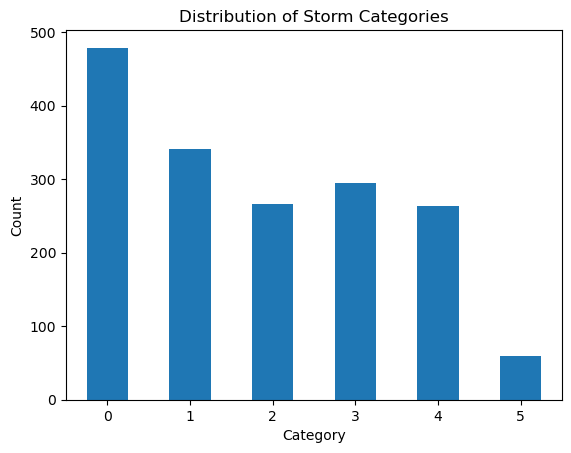

In [4]:
# I created the plot below to get a visual sense of the differences in categories
cat_counts = storms["CATEGORY"].value_counts().sort_index()
ax = cat_counts.plot.bar()
plt.xticks(rotation=0)
plt.title("Distribution of Storm Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

2) Plot the distribution of maximum wind speed by basin. Do all basins produce the same range of intensities?

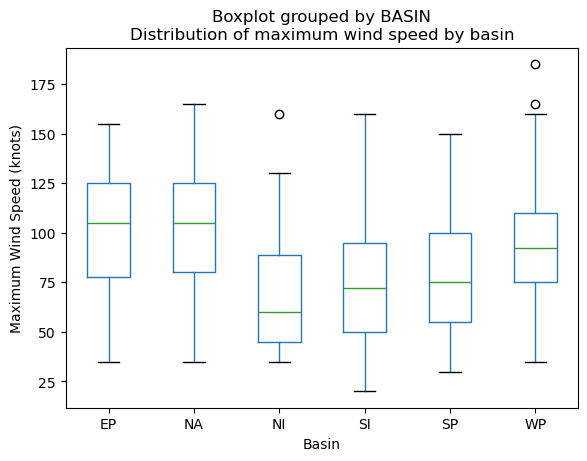

In [5]:
ax = storms.boxplot(column = "MAX_WIND", by = "BASIN", grid=False)
plt.xticks(rotation=0)
plt.title("Distribution of maximum wind speed by basin")
plt.xlabel("Basin")
plt.ylabel("Maximum Wind Speed (knots)")
plt.show()

_No, all basins do not produce the same range of intensities because their medians and the middle 50% of their ranges for maximum wind speed do not overlap much, even though the absolute minimum and maximum values are similar across the basins. The absolute minimum is ~30 knots for most basins (except for SI) and the absolute maximum is ~160 knots for most basins (except for NI)._

_SI has an absolute minimum of ~20 knots while the other basins have absolute minimums of ~30 knots._

_NI has an absolute maximum of ~130 knots (excluding the outlier) while the other basins have absolute maximums ranging from ~150 knots to ~165 knots._

_The median values vary widely, with EP and NA having medians of ~105 knots while NI has a median of ~60 knots. The middle 50% of the range (the Q3 and Q1 values) of NA and NI have very little overlap, with NA having a Q3 of ~80 knots and a Q1 of ~125 knots whie NI has a Q1 of ~45 knots and a Q3 of ~90 knots._

## Part 2: Linear regression: predicting intensity

3) Build a feature matrix from `MIN_PRES`, `MEAN_LAT`, `MEAN_LON` and `SEASON`, with
`MAX_WIND` as the target. Split into training and test sets with `random_state=0`.

In [6]:
wx = storms.sort_values("SEASON").reset_index(drop=True)
wx = wx.dropna().reset_index(drop=True)

features = ["MIN_PRES", "MEAN_LAT", "MEAN_LON", "SEASON"]

X_train_wind, X_test_wind, y_train_wind, y_test_wind = train_test_split(wx[features], wx["MAX_WIND"], test_size = 0.2, random_state = 0)

print(X_train_wind.shape, X_test_wind.shape)

(1362, 4) (341, 4)


4) Fit a `LinearRegression` and report the RMSE and $R^2$ on the test set.

In [7]:
reg = LinearRegression()
reg.fit(X_train_wind, y_train_wind)
pred = reg.predict(X_test_wind)

rmse = np.sqrt(mean_squared_error(y_test_wind, pred))
print(f"RMSE on the test years: {rmse:.2f} knots")
print(f"R^2 on the test years:  {r2_score(y_test_wind, pred):.3f}")

RMSE on the test years: 13.90 knots
R^2 on the test years:  0.784


5) Report the fitted coefficients. Which feature dominates, and does its sign make physical sense?

In [8]:
scaler = StandardScaler().fit(X_train_wind)
reg_std = LinearRegression().fit(scaler.transform(X_train_wind), y_train_wind)

for name, w in zip(features, reg_std.coef_):
    print(f"{name:8s} {w:+6.2f} knots per standard deviation")

MIN_PRES -25.04 knots per standard deviation
MEAN_LAT  +2.56 knots per standard deviation
MEAN_LON  -8.44 knots per standard deviation
SEASON    +0.29 knots per standard deviation


_The minimum pressure feature (MIN_PRES) dominates because it has the largest coefficient by magnitude of all the features. The weight of MIN_PRES tells us that the prediction moves by -25.04 knots per one standard deviation of that feature. Tropical cyclones are low pressure systems. Systems with lower central pressure result in stronger wind speeds, which is an inversely proportional relationship between pressure and wind speed. It makes sense that the coefficient has a negative sign, because as minimum pressure drops, maximum wind speed rises._

6) Plot predicted against observed wind speed for the test set, with a 1:1 line. Where does the model do worst, and is that the part of the range you would most want to get right?

In [9]:
wx["MAX_WIND"].min()

20.0

In [10]:
wx["MAX_WIND"].max()

185.0

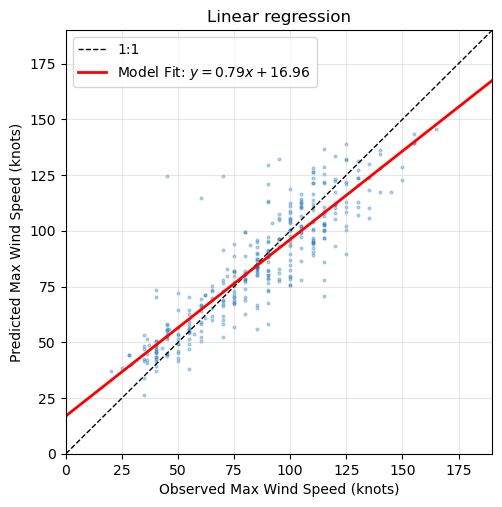

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test_wind, pred, s=4, alpha=0.3)
lims = [0, 190]
ax.plot(lims, lims, "k--", lw=1, label="1:1")

m, b = np.polyfit(y_test_wind, pred, 1)

sign = "+" if b >= 0 else "-"
fit_label = f"Model Fit: $y = {m:.2f}x {sign} {abs(b):.2f}$"

ax.plot(lims, np.array(lims) * m + b, "r-", lw=2, label=fit_label)

ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Observed Max Wind Speed (knots)")
ax.set_ylabel("Predicted Max Wind Speed (knots)")
ax.set_title("Linear regression")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

_The model does worst at the wind speed extremes, such as underpredicting higher wind speeds. For example, when the observed maximum wind speed is at ~150 knots, the predicted maximum wind speed is ~130 knots, demonstrating that the model is predicting lower values at the highest wind speeds, underestimating the extreme intensities. At the lower wind speeds, the model overpredicts slightly. For example, when the observed maximum wind speed is ~25 knots, the model predicts ~35 knots._ 

_The part of the range I would most want to get right is the higher wind speeds. When the model underpredicts higher wind speeds, forecasts would estimate lower wind speeds than actually occur, which could cause people to underestimate storm damage and be less likely to follow evacuation procedures, endangering more people than if the model more accurately predicted the higher wind speeds._

7) Compare against a baseline that always predicts the mean wind speed. How much better is your model? A model that cannot beat this baseline has demonstrated nothing.

In [12]:
wx_mean = y_train_wind.mean()
wx_mean

83.91042584434655

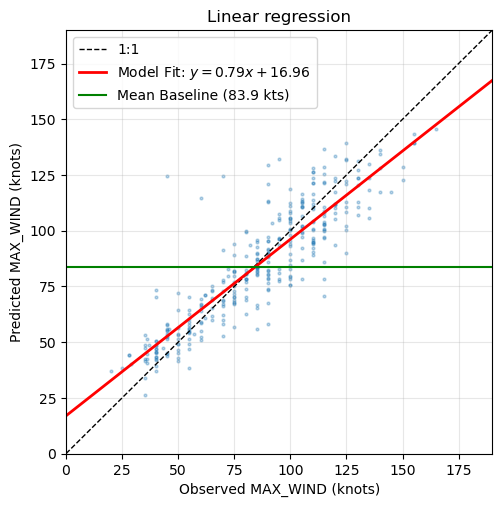

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test_wind, pred, s=4, alpha=0.3)
lims = [0, 190]
ax.plot(lims, lims, "k--", lw=1, label="1:1")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Observed MAX_WIND (knots)")
ax.set_ylabel("Predicted MAX_WIND (knots)")
ax.set_title("Linear regression")

sign = "+" if b >= 0 else "-"
fit_label = f"Model Fit: $y = {m:.2f}x {sign} {abs(b):.2f}$"

ax.plot(lims, np.array(lims) * m + b, "r-", lw=2, label=fit_label)

ax.axhline(wx_mean, color = "green", label=f"Mean Baseline ({wx_mean:.1f} kts)")

ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [14]:
mean_baseline = np.full_like(y_test_wind, fill_value=y_train_wind.mean())

print(f"Baseline Mean Prediction: {wx_mean:.3f} knots")

for name, p in [("Mean Baseline", mean_baseline), ("Linear Regression", pred)]:
    print(f"{name:1s} RMSE = {np.sqrt(mean_squared_error(y_test_wind, p)):.2f} knots")
    print(f"{name:1s} R^2 = {r2_score(y_test_wind, p):.3f}")

Baseline Mean Prediction: 83.910 knots
Mean Baseline RMSE = 29.96 knots
Mean Baseline R^2 = -0.004
Linear Regression RMSE = 13.90 knots
Linear Regression R^2 = 0.784


_My model (Linear Regression model) is much better than the mean wind speed baseline because my model has better performance in the Root Mean Squared Error (RMSE) and $R^2$ metrics._

_My model has a smaller RMSE value of 13.90 knots than the mean wind speed baseline, which has a RMSE value of 29.96 knots. This is more than a 50% reduction in the prediction error. This tells us that the Linear Regression model has a smaller average difference between the predicted values and actual values of maximum wind speed than predicting the mean wind speed every time._

_Additionally, the mean baseline has an  $R^2$ value of nearly zero (-0.004) while my model has a $R^2$ value of 0.784. My model explains 78.4% of the variance in the maximum wind speeds while the mean baseline explains none of the variance in the maximum wind speeds._

## Part 3: Logistic regression, will it be a major hurricane?

8) Using the same features, fit a `LogisticRegression` to predict `MAJOR`. Standardize the
features first. Use `make_pipeline(StandardScaler(), LogisticRegression())`. Why does
scaling matter here when it did not for linear regression?

In [15]:
wx["MAJOR"] = wx["CATEGORY"] >= 3

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

c_train, c_test = wx.loc[X_train_wind.index,"MAJOR"], wx.loc[X_test_wind.index,"MAJOR"]

major_clf = make_pipeline(StandardScaler(), LogisticRegression())
major_clf.fit(X_train_wind, c_train)
major_label = major_clf.predict(X_test_wind)

not_major = np.zeros_like(c_test)

Scaling matters here because it ensures that regularization works fairly across all the features.

The Logistic Regression function applies $L_2$ (Ridge) regularization, which penalizes large coefficients by adding a penalty term that is the sum of the squared weights to prevent overfitting. Unscaled features that have small numerical ranges need large coefficients to make an impact on the model output score, causing $L_2$ to disproportionately shrink their coefficients compared to features with large numerical ranges. Scaling makes sure that all features are penalized equally.

In contrast, Linear Regression (Ordinary Least Squares) applies a matrix formula to determine coefficients. Scaling a feature would just scale its corresponding coefficient inversely, which would not change the final predictions nor the $R^2$ value.

9) Report accuracy, precision, recall and the confusion matrix on the test set.

In [17]:
print(f"Not Major:          accuracy = {accuracy_score(c_test, not_major):.3f}")
print(f"Logistic regression: accuracy = {accuracy_score(c_test, major_label):.3f}")
print()
print("confusion matrix (rows = actually not major, actually major; columns = predicted not major, predicted major):")
print(confusion_matrix(c_test, major_label))
print()
print(f"Recall (of the major hurricanes, how many did it catch): {recall_score(c_test, major_label):.3f}")

Not Major:          accuracy = 0.604
Logistic regression: accuracy = 0.868

confusion matrix (rows = actually not major, actually major; columns = predicted not major, predicted major):
[[189  17]
 [ 28 107]]

Recall (of the major hurricanes, how many did it catch): 0.793


Balanced weights: Accuracy = 0.868, Precision = 0.863, Recall = 0.793


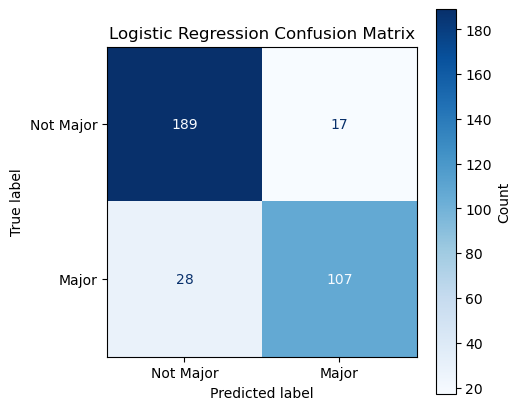

In [18]:
print(f"Balanced weights: Accuracy = {accuracy_score(c_test, major_label):.3f}, "
      f"Precision = {precision_score(c_test, major_label):.3f}, Recall = {recall_score(c_test, major_label):.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
display_matrix = ConfusionMatrixDisplay.from_predictions(
    c_test,
    major_label,
    display_labels=["Not Major", "Major"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

plt.colorbar(display_matrix.im_, ax=ax, label='Count')

ax.set_title("Logistic Regression Confusion Matrix")
plt.show()

10) Report the ROC AUC. Then compare accuracy against a classifier that always predicts the majority class. Which metric is more informative here, and why?

In [19]:
scores = major_clf.predict_proba(X_test_wind)[:,1]

auc_score = roc_auc_score(c_test, scores)
print(f"ROC AUC Score: {auc_score:.3f}")

ROC AUC Score: 0.929


In [20]:
baseline_accuracy = (c_test == np.zeros_like(c_test)).mean()
print(f"Accuracy for Baseline Classifier that always predicts the majority class: {baseline_accuracy:.3f}")

Accuracy for Baseline Classifier that always predicts the majority class: 0.604


In [21]:
c_test.value_counts(normalize=True)

MAJOR
False    0.604106
True     0.395894
Name: proportion, dtype: float64

In [22]:
log_regression_accuracy = major_clf.score(X_test_wind, c_test)
print(f"Accuracy for Logistic Regression: {log_regression_accuracy:.3f}")

Accuracy for Logistic Regression: 0.868


_The ROC AUC score is more informative here than the classifier that always predicts the majority class (baseline classifier). The ROC AUC score is 0.929 and the accuracy score of the baseline classifier is 0.604. This is because there is a class imbalance. The hurricane categories (major vs non-major) are not equally distributed since there are far more non-major hurricanes in the dataset than those that are major. The baseline classifier predicts "Not Major" every time, so it achieves 60.4% accuracy since non-major hurricanes make up 60.4% of the dataset. Accuracy for the baseline classifier only appears to perform relatively well because there are more non-major hurricanes in the dataset than major hurricanes._

_The ROC curve sweeps the classification threshold and plots the true-positive rate against the false-positive rate. The AUC summarizes overall performance in a single number (0.5 = random, 1.0 = perfect). ROC AUC evaluates how effective the model is at ranking positive occurrences (major hurricanes) above negative occurrences (non-major hurricanes) throughout all possible classification thresholds. Accuracy just evaluates the model performance at a fixed threshold of 0.5, so it is less informative than AUC ROC._ 

11) Extract the predicted probabilities and plot them against minimum pressure. Where does the model sit near 0.5, and what does that region represent physically?

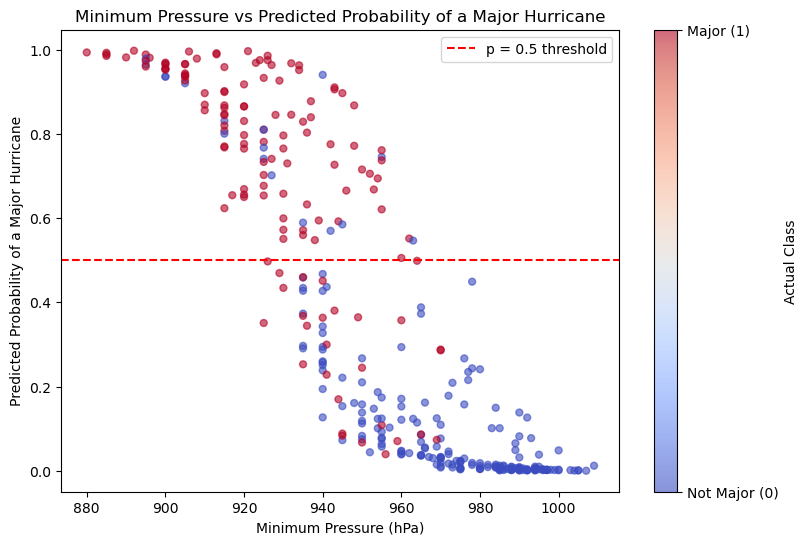

In [23]:
fig, ax = plt.subplots(figsize=(9, 6))
scatter = plt.scatter(X_test_wind["MIN_PRES"], scores, alpha = 0.6, s=25, c=c_test,cmap='coolwarm')
plt.xlabel("Minimum Pressure (hPa)")
plt.ylabel("Predicted Probability of a Major Hurricane")
plt.title("Minimum Pressure vs Predicted Probability of a Major Hurricane")
cb = plt.colorbar(scatter,ticks=[0, 1], label = "Actual Class")
cb.ax.set_yticklabels(["Not Major (0)", "Major (1)"])
plt.axhline(0.5, color="red", linestyle="--", label = "p = 0.5 threshold")
plt.legend()
plt.show()

_Near 0.5, the model sits near a minimum pressure value of approximately 945 hPa. Lower central atmospheric pressure is correlated with stronger pressure gradients, resulting in higher wind speeds. The ~945 hPa region represents the threshold of physical transition where the atmospheric pressure drops to a low enough value that the storm has a 50/50 chance of crossing the threshold to be considered a major hurricane. A major hurricane would be a category 3 or higher, which has a wind speed >= 96 knots._ 

## Part 4: Softmax regression, the full category scale

12) Fit a multi-class logistic regression to predict `CATEGORY` (six classes). Report the
classification report and a confusion matrix.

In [24]:
cat_names = ['Cat 0', 'Cat 1', 'Cat 2', 'Cat 3', 'Cat 4', 'Cat 5']

b_train = wx.loc[X_train_wind.index,"CATEGORY"]
b_test = wx.loc[X_test_wind.index,"CATEGORY"]

soft = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
soft.fit(X_train_wind, b_train)
b_pred = soft.predict(X_test_wind)


print(classification_report(b_test, b_pred, target_names = cat_names))

print("Class balance in training years: ", np.round(np.bincount(b_train) / len(b_train), 2))

print("confusion matrix: ")
print(confusion_matrix(b_test, b_pred))

              precision    recall  f1-score   support

       Cat 0       0.84      0.93      0.89        91
       Cat 1       0.48      0.68      0.56        56
       Cat 2       0.54      0.25      0.34        59
       Cat 3       0.54      0.51      0.53        68
       Cat 4       0.54      0.62      0.58        56
       Cat 5       1.00      0.27      0.43        11

    accuracy                           0.62       341
   macro avg       0.66      0.55      0.55       341
weighted avg       0.62      0.62      0.60       341

Class balance in training years:  [0.28 0.21 0.15 0.17 0.15 0.04]
confusion matrix: 
[[85  4  0  2  0  0]
 [12 38  2  2  2  0]
 [ 4 25 15 10  5  0]
 [ 0  7 11 35 15  0]
 [ 0  5  0 16 35  0]
 [ 0  0  0  0  8  3]]


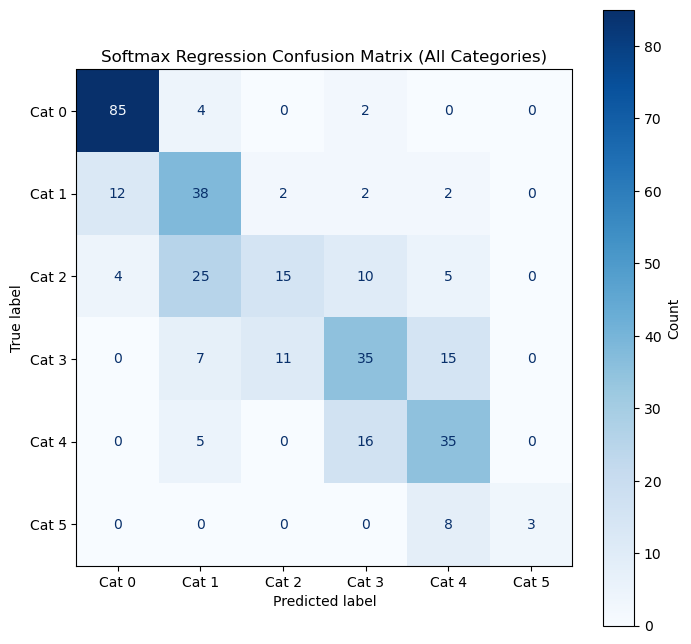

In [25]:
fig, ax = plt.subplots(figsize=(8,8))
display_matrix_2 = ConfusionMatrixDisplay.from_predictions(
    b_test,
    b_pred,
    display_labels=cat_names,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

plt.colorbar(display_matrix_2.im_, ax=ax, label='Count')

ax.set_title("Softmax Regression Confusion Matrix (All Categories)")
plt.show()

13) Which categories does the model confuse most? Explain why in terms of how the Saffir-Simpson categories are defined, pay attention to the width of each wind-speed bin.

_The model often confuses adjacent categories, for instance, confusing 1 with 2, and 2 with 3, and so on._

_The Saffir-Simpson categories are defined by the following ranges:_

| Category | Wind (kt) |
| --- | --- |
| Tropical storm | 34–63 |
| 1 | 64–82 |
| 2 | 83–95 |
| 3 | 96–112 |
| 4 | 113–136 |
| 5 | 137+ |

_For an individual category, Category 2 has the lowest recall value of 0.25 and thus the highest confusion. Out of 59 total Category 2 storms, 25 were misclassified as Category 1, and 10 were misclassified as Category 3, 4 were misclassified as Category 0, and 5 were misclassified as Category 4, for a total of 25+10+4+5 = 44 misclassified Category 2 hurricanes. Only 15 were correctly identified as Category 2. More Category 2 storms were misclassified than correctly predicted. This high confusion is mainly caused by the bin width. Category 2 has a very small range of 13 knots. Since the bin is so narrow, a small error in predicted wind speed can cause a storm to be misclassified as category 1 or category 3._

_The model also frequently confuses Category 5, with a low recall value of 0.27. Out of 11 Category 5 storms, 8 were misclassified as Category 4 and only 3 were correctly classified as Category 5. Unlike the other bin widths, Category 5 has a very wide range of >= 137 which is more open-ended. It also has high confusion due to class imbalance, since this Category represents only 11 of the storms in the dataset, and small prediction errors can occur near the threshold of 137 knots._


14) The category is a deterministic function of `MAX_WIND`, which you predicted in Part 2. Compare two approaches: (a) classify directly, and (b) predict wind speed with regression then apply the category thresholds. Which works better, and why might that be?

In [26]:
# Approach a
print(f"When classifying directly (approach a): accuracy = {accuracy_score(b_test, b_pred):.3f}")

When classifying directly (approach a): accuracy = 0.619


In [27]:
# Approach b
wind_pred = reg.predict(X_test_wind)
b_pred_reg = np.select([
    pred < 64,
    (pred >= 64) & (pred < 83),
    (pred >= 83) & (pred < 96),
    (pred >= 96) & (pred < 113),
    (pred >= 113) & (pred < 137),
    pred >= 137],[0,1,2,3,4,5], default = 0)

print(f"When predicting wind speed with regression then apply the category thresholds (approach b): accuracy = {accuracy_score(b_test, b_pred_reg):.3f}")

When predicting wind speed with regression then apply the category thresholds (approach b): accuracy = 0.581


_Approach A accuracy, Softmax Classification: 0.619_

_Approach B accuracy, Regression & Category Thresholds: 0.581_

_Classifying directly (Approach A) works better than predicting wind speed with regression and applying category thresholds (Approach B) because the former approach is optimized for categories and is more robust against boundary cutoffs, while the latter is optimized for continuous numbers. Softmax classification (Approach A) directly assigns probability scores to storm categories, while regression predicts exact wind speed numbers, treating a small prediction error in the middle of a category as the same as a prediction error near the boundary between categories. Approach A is more robust against boundary cutoffs because it evaluates category probabilities across all features, while Approach B can be affected by a small error in the wind speed close to a threshold, which can result in a storm being assigned the wrong category due to that small error._

## Part 5: Interpretation

15) Minimum pressure is by far the strongest predictor of maximum wind. Both are measurements
*of the same storm at the same time*. If your goal were to **forecast** intensity 24 hours
ahead, would pressure still be available as a feature? What does that tell you about the
difference between a model that explains and a model that predicts?

_No, pressure measured 24 hours after a particular time would not be available as a feature when making a forecast of intensity 24 hours ahead. Only current pressure at t = 0 or past pressure would be available. The value of pressure 24 hours in the future is unobservable data._

_A model that explains is one that focuses on the relationship between variables that are measured at the same point in time. This type of model is useful for understanding relationships that follow physical laws as long as the features are observed at the same time._

_A model that predicts is one that looks at features known before or during the time that the prediction is made to forecast an outcome at a future time._

16) IBTrACS combines reports from different agencies whose practices have changed over decades. Name one way this could bias a model trained on the full record, and suggest how you would check for it.

_This could bias a model if the agencies' frequencies of measurements and measurement technologies for maximum wind speeds and pressures have changed over decades. When using the full record, there could be bias based on inherent differences in measurement frequency (such as sparser records in past decades) and from older, less accurate technology. Additionally, new innovations like improved remote sensing have most likely improved the quality of atmospheric data in recent decades._

_I would check for this by grouping the data by era, such as 1960 to 1990 as Group 1 and 1990 to 2020 as Group 2. I would calculate the mean residuals separately for each group. If the mean residuals fall close to zero for one group but are consistently positive or negative (indicative of overpredicting or underpredicting), that tells us that the model has systematic biases due to the change in observation methods rather than physical changes in atmospheric conditions._